# 01 · Exploring the data
TCGA BRCA and LUAD RNA-seq (UCSC Xena, log2(RSEM+1)). Which samples are there, and how separable are tumor and normal before any modelling?

In [1]:
import os, sys
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display
from genepanel.cli import load_config, load_datasets
cfg = load_config('config/default.yaml')
TAB = f"{cfg['results_dir']}/tables"; FIG = f"{cfg['results_dir']}/figures"
pd.set_option('display.precision', 4)

In [2]:
datasets = load_datasets(cfg)
pd.DataFrame([{'cancer': d.cancer, 'task': d.task, 'samples': len(d.y), 'tumor': int(d.y.sum()),
               'normal': int((1-d.y).sum()), 'patients': len(set(d.groups)), 'genes_after_filter': len(d.genes)}
              for d in datasets])

,cancer,task,samples,tumor,normal,patients,genes_after_filter
0,BRCA,tumor_vs_normal,1211,1097,114,1097,17699
1,BRCA,stage1_vs_normal,296,182,114,276,17755
2,LUAD,tumor_vs_normal,573,514,59,515,17944
3,LUAD,stage1_vs_normal,333,274,59,304,17955


Stage distribution of tumors in the tumor-vs-normal task (Stage I tumors form the early-detection task).

In [3]:
pd.concat({d.cancer: pd.Series(d.stage[d.y == 1]).value_counts() for d in datasets if d.task == 'tumor_vs_normal'}, axis=1)

,BRCA,LUAD
II,621,122
III,250,84
I,182,274
NA,24,8
IV,20,26


## PCA: is the tumor/normal split visible without labels?

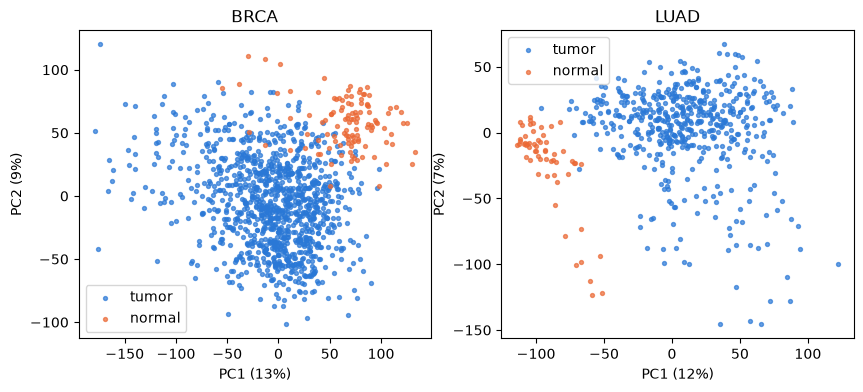

In [4]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
tvn = [d for d in datasets if d.task == 'tumor_vs_normal']
fig, axes = plt.subplots(1, len(tvn), figsize=(5 * len(tvn), 4))
for ax, d in zip(np.atleast_1d(axes), tvn):
    pc = PCA(2).fit(StandardScaler().fit_transform(d.X))
    Z = pc.transform(StandardScaler().fit_transform(d.X))
    for lab, col, name in [(1, '#2a78d6', 'tumor'), (0, '#eb6834', 'normal')]:
        ax.scatter(Z[d.y == lab, 0], Z[d.y == lab, 1], s=8, c=col, label=name, alpha=0.7)
    ax.set(title=d.cancer, xlabel=f'PC1 ({pc.explained_variance_ratio_[0]:.0%})', ylabel=f'PC2 ({pc.explained_variance_ratio_[1]:.0%})')
    ax.legend()

## How strong is the best single gene?
If one gene already separates tumor from normal, the 'small panel' question is mostly answered by the data, not the method.

In [5]:
from sklearn.metrics import roc_auc_score
rows = []
for d in datasets:
    auc = np.array([roc_auc_score(d.y, d.X[:, j]) for j in range(d.X.shape[1])])
    auc = np.maximum(auc, 1 - auc)  # direction-free
    top = np.argsort(-auc)[:5]
    rows.append({'cancer': d.cancer, 'task': d.task, 'genes_auc_ge_0.95': int((auc >= 0.95).sum()),
                 'genes_auc_ge_0.90': int((auc >= 0.90).sum()),
                 'top5 (in-sample AUC)': ', '.join(f'{d.genes[j]} {auc[j]:.3f}' for j in top)})
pd.DataFrame(rows)

,cancer,task,genes_auc_ge_0.95,genes_auc_ge_0.90,top5 (in-sample AUC)
0,BRCA,tumor_vs_normal,459,1452,"FIGF 0.995, SDPR 0.994, MMP11 0.994, CD300LG 0..."
1,BRCA,stage1_vs_normal,417,1349,"ADAMTS5 0.997, SCN4B 0.997, MMP11 0.996, FIGF ..."
2,LUAD,tumor_vs_normal,779,1975,"STX11 0.999, EMP2 0.999, AGER 0.998, TNNC1 0.9..."
3,LUAD,stage1_vs_normal,748,1910,"STX11 1.000, EMP2 0.999, CAV1 0.998, AGER 0.99..."


*Note:* these single-gene AUCs are in-sample (gene chosen on all data), so they are optimistic. The CV results in notebook 02 select genes inside each fold.